# Ensembling !!!

In [1]:
import os, glob, gc, math, re, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import timm
from timm.layers import resample_abs_pos_embed
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from scipy.optimize import linear_sum_assignment
try:
    import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING); HAS_OPTUNA = True
except Exception:
    HAS_OPTUNA = False

# ======================= CONFIG =======================
COMP_DIR = "/kaggle/input/competitions/ai-of-god-5/participant_data"
B = "/kaggle/input/datasets"
SOURCES = [   # fam = model family (used by family-balanced averaging)
    dict(name="swin",   kind="swin", dir=f"{B}/mayankmishra2006/swin-aog-best-wts", fam="swin",   imgs=None,  check_split=False, ctag="swin"),
    dict(name="dino",   kind="vit",  dir=f"{B}/mayankmishra2006/dino-aog-best",     fam="dinov2", imgs=(224,), check_split=False, ctag="dino"),
    dict(name="dino2n", kind="vit",  dir=f"{B}/mayankmishra2006/dino-v2-new",       fam="dinov2", imgs=(308,), check_split=True),
    dict(name="dino3n", kind="hfv3", dir=f"{B}/mayankmishra2006/dino-v3-new-wts",   fam="dinov3", imgs=(384,), check_split=True),
    dict(name="eva02",  kind="npz",  dir=f"{B}/satyaroopchatterjee/satyas-eva02",   fam="eva"),
    dict(name="dino3",  kind="npz",  dir=f"{B}/satyaroopchatterjee/satyas-dino-v3", fam="dinov3"),
]
BS = 64
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
TTA_HFLIP = True
FOLD_SEED, N_FOLDS = 42, 5
N_TRIALS = 200
MIN_GAIN = 0.002        # a fancier option must beat the simple one by this much on dev
EXT_MARGIN = 0.003      # holdout-only model is kept unless it lowers holdout F1 by more than this
UNVAL_SHARE = 0.20      # total share for models with no honest dev score
REUSE = True
# ======================================================
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("cuda:", torch.cuda.is_available(), "| optuna:", HAS_OPTUNA)

# ---------------- data ----------------
train_df = pd.read_csv(f"{COMP_DIR}/train.csv")
img_col, label_col = "image_id", "animal_class"
CLASSES = sorted(train_df[label_col].unique().tolist()); NC = len(CLASSES)
y_all = train_df[label_col].map({c: i for i, c in enumerate(CLASSES)}).values
train_paths = np.array([f"{COMP_DIR}/train_images/{i}" for i in train_df[img_col]])
sub = pd.read_csv(f"{COMP_DIR}/sample_submission.csv"); ids = sub["image_id"].tolist()
test_paths = np.array([f"{COMP_DIR}/test_images/{i}" for i in ids])
assert os.path.exists(test_paths[0]) and os.path.exists(train_paths[0])
print(f"classes: {NC} | train: {len(train_paths)} | test: {len(test_paths)}")

skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=FOLD_SEED)
fold_val_idx = [v for _, v in skf.split(train_paths, y_all)]
dev_idx = np.concatenate(fold_val_idx); y_dev = y_all[dev_idx]; ND = len(dev_idx)
pos_in_dev = np.full(len(train_paths), -1); pos_in_dev[dev_idx] = np.arange(ND)
stem = lambda s: os.path.splitext(str(s))[0]
tr_pos = {stem(os.path.basename(p)): i for i, p in enumerate(train_paths)}

class DS(Dataset):
    def __init__(s, paths, size):
        s.p = paths; s.t = T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(MEAN, STD)])
    def __len__(s): return len(s.p)
    def __getitem__(s, i): return s.t(Image.open(s.p[i]).convert("RGB"))

@torch.no_grad()
def predict(model, paths, size):
    model.eval().to(dev); out = []
    for x in DataLoader(DS(paths, size), batch_size=BS, num_workers=2):
        x = x.to(dev)
        with torch.autocast(dev, enabled=(dev == "cuda")):
            p = F.softmax(model(x).float(), 1)
            if TTA_HFLIP: p = (p + F.softmax(model(torch.flip(x, [3])).float(), 1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

def predict_c(c, m, paths, size):
    p = predict(m, paths, size)
    return p if c.get("colperm") is None else p[:, c["colperm"]]

# ---------------- checkpoint loading ----------------
_cache = {}
def load_ck(path):
    if _cache.get("path") == path: return _cache["sd"], _cache["meta"]
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, nn.Module): ck = ck.state_dict()
    meta = ck if isinstance(ck, dict) else {}
    if isinstance(ck, dict):
        for k in ("model_state", "model_state_dict", "state_dict", "model", "net"):
            if k in ck and isinstance(ck[k], dict): ck = ck[k]; break
    sd = {k.replace("module.", "", 1): v for k, v in ck.items() if torch.is_tensor(v)}
    if not any(re.search(r"head\.\d+\.weight$", k) for k in sd):      # plain Linear head -> treat as Sequential(Linear)
        for k in list(sd):
            m_ = re.fullmatch(r"(.*?)head\.(weight|bias)", k)
            if m_: sd[f"{m_.group(1)}head.0.{m_.group(2)}"] = sd.pop(k)
    _cache.update(path=path, sd=sd, meta={k: v for k, v in meta.items() if k not in ("optimizer",)})
    return sd, _cache["meta"]

def diag(path):
    try:
        sd, _ = load_ck(path); ks = list(sd); print(f"    {len(ks)} tensors; sample keys:")
        for k in ks[:6] + ks[-6:]: print("      ", k, tuple(sd[k].shape))
    except Exception as e: print("    (cannot read ckpt)", e)

def find_ckpts(d):
    fs = sorted(glob.glob(f"{d}/**/*.pt", recursive=True) + glob.glob(f"{d}/**/*.pth", recursive=True))
    best = [f for f in fs if "best" in os.path.basename(f).lower()]
    return best or fs

# ---------------- architectures (inferred from checkpoint keys) ----------------
ACTS = {"gelu": nn.GELU, "relu": nn.ReLU, "silu": nn.SiLU}
SIZES = {384: "small", 768: "base", 1024: "large", 1536: "giant"}

def build_head(sd, root, idxs, act):
    layers, need_act = [], False
    for i in range(idxs[-1] + 1):
        if i in idxs:
            w = sd[f"{root}head.{i}.weight"]
            if w.ndim == 2: layers.append(nn.Linear(w.shape[1], w.shape[0])); need_act = True
            elif f"{root}head.{i}.running_mean" in sd: layers.append(nn.BatchNorm1d(w.shape[0])); need_act = False
            else: layers.append(nn.LayerNorm(w.shape[0])); need_act = False
        elif need_act: layers.append(ACTS[act]()); need_act = False
        else: layers.append(nn.Dropout(0.0))
    return nn.Sequential(*layers)

class SwinNet(nn.Module):
    def __init__(s, name, sd, act):
        super().__init__()
        s.backbone = timm.create_model(name, pretrained=False, num_classes=0)
        idxs = sorted(int(m.group(1)) for k in sd for m in [re.fullmatch(r"head\.(\d+)\.weight", k)] if m)
        s.head = build_head(sd, "", idxs, act)
    def forward(s, x): return s.head(s.backbone(x))

class GenNet(nn.Module):
    def __init__(s, bb, head, pool, gem_shape):
        super().__init__()
        s.backbone, s.head, s.pool = bb, head, pool.split("_")
        s.gem_p = nn.Parameter(torch.ones(gem_shape) * 3.0) if gem_shape is not None else None
    def forward(s, x):
        t = s.backbone.forward_features(x)
        n = getattr(s.backbone, "num_prefix_tokens", 1)
        cls, pat = t[:, 0].float(), t[:, n:].float()
        feats = {"cls": cls, "avg": pat.mean(1)}
        if s.gem_p is not None:
            p = s.gem_p.float(); feats["gem"] = pat.clamp(min=1e-6).pow(p).mean(1).pow(1.0 / p)
        return s.head(torch.cat([feats[k] for k in s.pool], 1))

# ---- HuggingFace-format DINOv3 (dino3n): keys backbone.embeddings.* / backbone.model.layer.* / backbone.norm.* ----
class HFV3Net(nn.Module):
    def __init__(s, sd, pool):
        super().__init__()
        from transformers import DINOv3ViTConfig, DINOv3ViTModel
        D = sd["backbone.norm.weight"].shape[0]
        L = len({int(m.group(1)) for k in sd for m in [re.match(r"backbone\.model\.layer\.(\d+)\.", k)] if m})
        gated = "backbone.model.layer.0.mlp.gate_proj.weight" in sd
        inter = sd["backbone.model.layer.0.mlp.gate_proj.weight" if gated else "backbone.model.layer.0.mlp.up_proj.weight"].shape[0]
        s.nreg = sd["backbone.embeddings.register_tokens"].shape[1] if "backbone.embeddings.register_tokens" in sd else 0
        cfg = DINOv3ViTConfig(hidden_size=D, intermediate_size=inter, num_hidden_layers=L, num_attention_heads=D // 64,
                              patch_size=sd["backbone.embeddings.patch_embeddings.weight"].shape[-1],
                              num_register_tokens=s.nreg, hidden_act="silu" if gated else "gelu", use_gated_mlp=gated,
                              key_bias="backbone.model.layer.0.attention.k_proj.bias" in sd)
        s.bb = DINOv3ViTModel(cfg); s.pool = pool
        idxs = sorted(int(m.group(1)) for k in sd for m in [re.fullmatch(r"head\.(\d+)\.weight", k)] if m)
        s.head = build_head(sd, "", idxs, "gelu")
    def forward(s, x):
        h = s.bb(pixel_values=x).last_hidden_state.float()
        f = h[:, 0] if s.pool == "cls" else h[:, 1 + s.nreg:].mean(1)
        return s.head(f)

def hfv3_sd(sd):
    out = {}
    for k, v in sd.items():
        if k.startswith("backbone.model."): out["bb." + k[len("backbone.model."):]] = v
        elif k.startswith("backbone.embeddings."): out["bb.embeddings." + k[len("backbone.embeddings."):]] = v
        elif k.startswith("backbone.norm."): out["bb.norm." + k[len("backbone.norm."):]] = v
        else: out[k] = v
    return out

def info_vit(sd):
    P = next((k[:-len("patch_embed.proj.weight")] for k in sd if k.endswith("patch_embed.proj.weight")), None)
    assert P is not None, "no patch_embed.proj.weight (not a timm/DINO/EVA-style ViT, or custom wrapper)"
    root = next((m.group(1) for k in sd for m in [re.fullmatch(r"(.*?)head\.(\d+)\.weight", k)] if m), None)
    assert root is not None, "no head weights found"
    w = sd[P + "patch_embed.proj.weight"]; D, patch = w.shape[0], w.shape[-1]
    reg = any((P + k) in sd for k in ("register_tokens", "reg_token", "storage_tokens"))
    s = SIZES[D]
    if patch == 14:
        names = [f"vit_{s}_patch14_reg4_dinov2"] if reg else [f"vit_{s}_patch14_dinov2", f"eva02_{s}_patch14_224", f"eva02_{s}_patch14_448"]
    elif patch == 16: names = [f"vit_{s}_patch16_dinov3", f"vit_{s}_patch16_dinov3_qkvb"]
    else: raise ValueError(f"unknown patch size {patch}")
    idxs = sorted(int(m.group(1)) for k in sd for m in [re.fullmatch(re.escape(root) + r"head\.(\d+)\.weight", k)] if m)
    w0 = sd[f"{root}head.{idxs[0]}.weight"]
    return dict(P=P, root=root, D=D, patch=patch, names=names, idxs=idxs,
                head_in=(w0.shape[0] if w0.ndim == 1 else w0.shape[1]), gem=sd.get(root + "gem_p"))

def canon(sd, P, root):
    out = {}
    for k, v in sd.items():
        if k.startswith(root + "head."): out["head." + k[len(root + "head."):]] = v
        elif k == root + "gem_p": out["gem_p"] = v
        elif k.startswith(P): out["backbone." + k[len(P):]] = v
        else: out[k] = v
    return out

def remap_vit(sd, bb, img, patch):
    sd = dict(sd); ms = bb.state_dict()
    if "mask_token" not in ms: sd.pop("backbone.mask_token", None)
    for old in ("register_tokens", "storage_tokens"):
        if f"backbone.{old}" in sd and "reg_token" in ms: sd["backbone.reg_token"] = sd.pop(f"backbone.{old}")
    if "backbone.pos_embed" in sd and "pos_embed" in ms:
        pe, target, g = sd["backbone.pos_embed"], ms["pos_embed"].shape[1], img // patch
        if pe.shape[1] != target:
            has_cls = math.isqrt(pe.shape[1]) ** 2 != pe.shape[1]
            if getattr(bb, "no_embed_class", False):
                if has_cls: sd["backbone.cls_token"] = sd["backbone.cls_token"] + pe[:, :1]; pe = pe[:, 1:]
                n = math.isqrt(pe.shape[1])
                if n != g: pe = resample_abs_pos_embed(pe, new_size=(g, g), old_size=(n, n), num_prefix_tokens=0)
            else:
                npf = 1 if has_cls else 0; n = math.isqrt(pe.shape[1] - npf)
                pe = resample_abs_pos_embed(pe, new_size=(g, g), old_size=(n, n), num_prefix_tokens=npf)
            sd["backbone.pos_embed"] = pe
    return sd

def check_load(m, sd2):
    res = m.load_state_dict(sd2, strict=False)
    miss = [k for k in res.missing_keys if not any(s in k for s in ("relative_position_index", "attn_mask", "rope", "inv_freq"))]
    unex = [k for k in res.unexpected_keys if not any(s in k for s in ("rope", "inv_freq"))]
    assert not miss and not unex, f"load mismatch! missing={miss[:4]} unexpected={unex[:4]}"

def make(kind, path, v):
    sd, _ = load_ck(path)
    if kind == "swin":
        rows = sd["backbone.layers.0.blocks.0.attn.relative_position_bias_table"].shape[0]
        name, size = {169: ("swin_base_patch4_window7_224", 224), 529: ("swin_base_patch4_window12_384", 384)}[rows]
        assert sd["backbone.norm.weight"].shape[0] == 1024, "not swin-base"
        m = SwinNet(name, sd, v["act"]); check_load(m, sd); return m, size
    if kind == "hfv3":
        m = HFV3Net(sd, v["pool"]); check_load(m, hfv3_sd(sd)); return m, v["img"]
    inf = info_vit(sd); errs = []
    for name in inf["names"]:
        try:
            bb = timm.create_model(name, pretrained=False, num_classes=0, img_size=v["img"])
            head = build_head(sd, inf["root"], inf["idxs"], v["act"])
            m = GenNet(bb, head, v["pool"], inf["gem"].shape if inf["gem"] is not None else None)
            check_load(m, remap_vit(canon(sd, inf["P"], inf["root"]), bb, v["img"], inf["patch"]))
            return m, v["img"]
        except Exception as e: errs.append(f"{name}: {str(e)[:160]}")
    raise RuntimeError("no timm architecture matched -> " + " | ".join(errs))

def vit_variants(sd, imgs):
    inf = info_vit(sd); D, hin, has_gem = inf["D"], inf["head_in"], inf["gem"] is not None
    if hin == 2 * D: pools = ["cls_gem", "gem_cls"] if has_gem else ["cls_avg", "avg_cls"]
    elif hin == D:   pools = (["gem"] if has_gem else []) + ["cls", "avg"]
    else: raise ValueError(f"head input {hin} != D={D} (custom pooling head, cannot load)")
    print(f"  inferred: {inf['names'][0]}... | head_in={hin} | gem_p={has_gem}")
    return [dict(pool=p, act=a, img=i) for p in pools for a in ("gelu", "relu") for i in imgs if i % inf["patch"] == 0]

nll = lambda p, y: float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-9, 1)).mean())
mf1 = lambda y, p: f1_score(y, p.argmax(1), average="macro")

def pick(c, variants, n=256):
    idx = np.random.RandomState(0).choice(len(train_paths), n, replace=False)
    best, best_key = None, (-1, 0)
    for v in variants:
        m, size = make(c["kind"], c["weights"][0], v)
        p = predict_c(c, m, train_paths[idx], size); acc, l = (p.argmax(1) == y_all[idx]).mean(), nll(p, y_all[idx])
        print(f"  [{c['name']}] {v} -> acc {acc:.3f} nll {l:.4f}")
        if (round(acc, 4), -l) > best_key: best, best_key = v, (round(acc, 4), -l)
        del m; gc.collect(); torch.cuda.empty_cache()
    print(f"  [{c['name']}] chosen: {best} (acc {best_key[0]:.3f})")
    return best, best_key[0]

def prepare_ckpt(c):
    ws = c["weights"]; assert ws, "no checkpoint files found"
    sd0, meta = load_ck(ws[0]); c["colperm"] = None
    cl = meta.get("classes")
    if cl is None and isinstance(meta.get("class_to_idx"), dict):
        cl = [k for k, _ in sorted(meta["class_to_idx"].items(), key=lambda kv: kv[1])]
    if cl is not None:
        cl = [str(x) for x in cl]
        if cl != CLASSES:
            assert set(cl) == set(CLASSES), "ckpt classes differ from train.csv classes"
            c["colperm"] = [cl.index(x) for x in CLASSES]; print("  class order differs from sorted -> remapping columns")
        else: print("  ckpt class order == sorted classes")
    for k in ("fold", "val_macro_f1", "epoch"):
        if k in meta: print(f"  ckpt {k}: {meta[k]}")
    cfg = meta.get("cfg"); cfgd = cfg if isinstance(cfg, dict) else getattr(cfg, "__dict__", {})
    if cfg is not None: print("  cfg:", str(cfgd or cfg)[:300])
    extra = [int(cfgd[k]) for k in ("img_size", "image_size", "size", "img", "resolution", "input_size")
             if isinstance(cfgd.get(k), (int, float)) and int(cfgd[k]) >= 64]
    if c["kind"] == "swin": variants = [dict(act=a) for a in ("gelu", "relu", "silu")]
    elif c["kind"] == "hfv3":
        variants = [dict(pool=p, act="gelu", img=i) for p in ("cls", "avg") for i in sorted(set(c["imgs"]) | set(extra))]
    else: variants = vit_variants(sd0, tuple(sorted(set(c["imgs"]) | set(extra))))
    c["v"], acc = pick(c, variants)
    assert acc >= 0.5, f"best sample acc {acc:.3f} ~ chance: weights load but pooling/normalization/forward guess is wrong"
    c["dev"] = "oof" if len(ws) == N_FOLDS else "none"
    if c["dev"] == "none": print(f"  {len(ws)} files != {N_FOLDS} folds -> test-only (unvalidated)")
    if c["dev"] == "oof" and c["check_split"]:
        m, size = make(c["kind"], ws[0], c["v"]); rs = np.random.RandomState(1)
        va = rs.choice(fold_val_idx[0], 300, replace=False)
        tr = rs.choice(np.setdiff1d(np.arange(len(train_paths)), fold_val_idx[0]), 300, replace=False)
        a, b = nll(predict_c(c, m, train_paths[va], size), y_all[va]), nll(predict_c(c, m, train_paths[tr], size), y_all[tr])
        del m; gc.collect(); torch.cuda.empty_cache()
        ok = a / max(b, 1e-6) >= 1.3
        print(f"  split check: val NLL {a:.4f} vs train NLL {b:.4f} (ratio {a/max(b,1e-6):.2f}) -> " + ("consistent with seed" if ok else "CANNOT confirm folds -> unvalidated"))
        if not ok: c["dev"] = "none"
    if c.get("ctag") is None: c["ctag"] = f"{c['name']}_{c['v'].get('img','')}_{c['v'].get('pool','')}"

def run_ckpt(c):
    tag, is_oof = c["ctag"], c["dev"] == "oof"
    tpf, dpf = f"/kaggle/working/test_probs_{tag}.npy", f"/kaggle/working/dev_probs_{tag}.npy"
    if REUSE and os.path.exists(tpf) and (not is_oof or os.path.exists(dpf)):
        tp = np.load(tpf); dp = np.load(dpf) if is_oof else None
        if tp.shape == (len(test_paths), NC) and (dp is None or dp.shape == (ND, NC)):
            print("  reused saved probs"); return dp, tp
    dp, tp = [], []
    for k, w in enumerate(c["weights"]):
        m, size = make(c["kind"], w, c["v"])
        if is_oof:
            p = predict_c(c, m, train_paths[fold_val_idx[k]], size); dp.append(p)
            print(f"  fold{k} held-out acc: {(p.argmax(1) == y_all[fold_val_idx[k]]).mean():.4f}")
        tp.append(predict_c(c, m, test_paths, size)); del m; gc.collect(); torch.cuda.empty_cache()
    tp = np.mean(tp, 0); np.save(tpf, tp)
    dp = np.concatenate(dp) if is_oof else None
    if is_oof: np.save(dpf, dp)
    return dp, tp

def ext_from_npz(path):
    z = np.load(path, allow_pickle=True)
    assert all(k in z.files for k in ("val_ids", "y_val", "test_ids", "classes")), f"unexpected npz keys: {z.files}"
    zc = [str(x) for x in z["classes"]]; assert set(zc) == set(CLASSES)
    perm = [zc.index(x) for x in CLASSES]
    v_idx = np.array([tr_pos[stem(i)] for i in z["val_ids"]])
    assert (np.array([zc[i] for i in z["y_val"]]) == np.array([CLASSES[i] for i in y_all[v_idx]])).all(), "npz labels != train.csv"
    te_pos = {stem(t): i for i, t in enumerate(z["test_ids"])}; te_rows = np.array([te_pos[stem(i)] for i in ids])
    sufs = [s for s in ("", "_flip", "_perm") if f"val_probs{s}" in z.files and f"test_probs{s}" in z.files]
    assert sufs, "no val_probs/test_probs in npz"
    for s in sufs: print(f"    variant {s or '_base'}: holdout F1 {mf1(y_all[v_idx], z[f'val_probs{s}'][:, perm]):.4f}")
    vp = np.mean([z[f"val_probs{s}"][:, perm] for s in sufs], 0)
    tp = np.mean([z[f"test_probs{s}"][te_rows][:, perm] for s in sufs], 0)
    return pos_in_dev[v_idx], vp, tp

# ---------------- load every source ----------------
M = {}
for c in SOURCES:
    n = c["name"]; print(f"\n=== {n} ({c['dir'].split('/')[-1]}) ===")
    done = False
    if c["kind"] != "npz":
        c["weights"] = find_ckpts(c["dir"]); print(f"  {len(c['weights'])} checkpoint files")
        try:
            prepare_ckpt(c); vp, tp = run_ckpt(c)
            M[n] = dict(fam=c["fam"], kind="oof" if c["dev"] == "oof" else "unval", val_p=vp, rows=np.arange(ND) if vp is not None else None, test_p=tp)
            done = True
        except Exception as e:
            print(f"  !! checkpoint route failed: {type(e).__name__}: {str(e)[:350]}")
            if c["weights"]: diag(c["weights"][0])
    if not done:
        for f in sorted(glob.glob(f"{c['dir']}/**/*.npz", recursive=True)):
            try:
                rows, vp, tp = ext_from_npz(f)
                M[n] = dict(fam=c["fam"], kind="ext", val_p=vp, rows=rows, test_p=tp); done = True
                print(f"  using saved probs {os.path.basename(f)} ({len(rows)} holdout images)"); break
            except Exception as e: print(f"  npz {os.path.basename(f)} unusable: {type(e).__name__}: {str(e)[:200]}")
    if not done: print(f"  !! {n} SKIPPED")
assert M, "no model could be loaded"

# ---------------- calibration (temperature) + per-model scores ----------------
def tscale(p, Tm):
    z = np.log(np.clip(p, 1e-9, 1)) / Tm; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def fitT(p, y):
    grid = np.exp(np.linspace(np.log(0.3), np.log(5), 60)); return float(min(grid, key=lambda t: nll(tscale(p, t), y)))

print("\n===== per-model scores (own honest eval rows) =====")
for n, m in M.items():
    if m["val_p"] is None: m["T"] = 1.0; m["lk"] = None; print(f"{n:7s} [{m['kind']}] fam={m['fam']}: test-only, no dev score"); continue
    y = y_dev[m["rows"]]; m["T"] = fitT(m["val_p"], y)
    m["lk"] = np.full(ND, -1); m["lk"][m["rows"]] = np.arange(len(m["rows"]))
    print(f"{n:7s} [{m['kind']}] fam={m['fam']}: F1 {mf1(y, m['val_p']):.4f} | NLL {nll(m['val_p'], y):.4f} -> {nll(tscale(m['val_p'], m['T']), y):.4f} after T={m['T']:.2f} | n={len(y)}")

V = lambda n, H: M[n]["val_p"][M[n]["lk"][H]]
def common(names):
    H = np.arange(ND)
    for n in names: H = H[M[n]["lk"][H] >= 0]
    return H

# ---------------- ensembling recipes ----------------
RECIPES = {"eq_prob": (False, "prob"), "eq_log": (False, "log"), "temp_prob": (True, "prob"),
           "temp_log": (True, "log"), "fam_prob": (False, "fam"), "fam_temp": (True, "fam")}
def geo(Qs, w=None):
    w = np.ones(len(Qs)) / len(Qs) if w is None else np.asarray(w)
    z = sum(wi * np.log(np.clip(q, 1e-7, 1)) for wi, q in zip(w, Qs)); z = np.exp(z - z.max(1, keepdims=True)); return z / z.sum(1, keepdims=True)
def combine(P, names, recipe, W=None):
    if recipe == "wtd":
        mw = np.mean(list(W["w"].values())); ww = np.array([W["w"].get(n, mw) for n in names]); ww = ww / ww.sum()
        Q = [tscale(P[n], M[n]["T"]) for n in names]
        return sum(w * q for w, q in zip(ww, Q)) if W["mode"] == "prob" else geo(Q, ww)
    tmp, agg = RECIPES[recipe]
    Q = {n: (tscale(P[n], M[n]["T"]) if tmp else P[n]) for n in names}
    if agg == "prob": return np.mean([Q[n] for n in names], 0)
    if agg == "log": return geo([Q[n] for n in names])
    fams = {}
    for n in names: fams.setdefault(M[n]["fam"], []).append(Q[n])
    return np.mean([np.mean(v, 0) for v in fams.values()], 0)
def eval_set(names, H, recipe, W=None):
    Bp = combine({n: V(n, H) for n in names}, names, recipe, W); return mf1(y_dev[H], Bp), Bp

# ---- stage 1: choose the recipe on the full OOF dev set ----
oofs = [n for n in M if M[n]["kind"] == "oof"]
recipe, W, B_dev = "fam_temp", None, None
if oofs:
    print(f"\n===== recipe comparison on OOF dev ({ND} images), models: {oofs} =====")
    res = {}
    for r in RECIPES:
        f, Bp = eval_set(oofs, np.arange(ND), r); res[r] = (f, nll(Bp, y_dev)); print(f"{r:10s}: F1 {f:.4f} | NLL {res[r][1]:.4f}")
    top = max(v[0] for v in res.values())
    recipe = min((r for r in res if res[r][0] >= top - 0.001), key=lambda r: res[r][1])
    best_f = res[recipe][0]; print(f"-> best simple recipe: {recipe} (F1 {best_f:.4f}; ties within 0.001 resolved by NLL)")
    if len(oofs) > 1 and HAS_OPTUNA:
        Pd = {n: M[n]["val_p"] for n in oofs}
        def objective(trial):
            mode = trial.suggest_categorical("mode", ["prob", "logprob"]); w = {n: trial.suggest_float(f"w_{n}", 0.0, 1.0) for n in oofs}
            if sum(w.values()) < 1e-6: return 0.0
            return mf1(y_dev, combine(Pd, oofs, "wtd", dict(mode="prob" if mode == "prob" else "log", w=w)))
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0)); study.optimize(objective, n_trials=N_TRIALS)
        tw = {n: study.best_params[f"w_{n}"] for n in oofs}; tot = sum(tw.values())
        print(f"optuna weighted: F1 {study.best_value:.4f} | " + ", ".join(f"{n}={tw[n]/tot:.2f}" for n in oofs))
        if study.best_value - best_f >= MIN_GAIN:
            recipe, W = "wtd", dict(mode="prob" if study.best_params["mode"] == "prob" else "log", w=tw); print("-> using optuna weights")
        else: print(f"-> optuna gain < {MIN_GAIN}: not used (would fit dev noise)")
    B_dev = combine({n: M[n]["val_p"] for n in oofs}, oofs, recipe, W)
    print(f"DEV macro-F1 of final OOF ensemble ({recipe}): {mf1(y_dev, B_dev):.4f}")

# ---- stage 2: add holdout-only models (dino3, eva02) if they don't hurt ----
final_names = list(oofs)
for e in [n for n in M if M[n]["kind"] == "ext"]:
    cand = final_names + [e]; H = common(cand)
    if not final_names or len(H) < 100: final_names.append(e); print(f"+ {e}: too little overlap to validate -> included"); continue
    fw, fo = eval_set(cand, H, recipe, W)[0], eval_set(final_names, H, recipe, W)[0]
    keep = fw >= fo - EXT_MARGIN
    print(f"{'+' if keep else '-'} {e}: holdout F1 ({len(H)} imgs) with {fw:.4f} vs without {fo:.4f} -> {'included' if keep else 'dropped'}")
    if keep: final_names.append(e)
unv = [n for n in M if M[n]["kind"] == "unval"]

# ---------------- final test blend ----------------
def finish(names, rec, W_=None):
    P = combine({n: M[n]["test_p"] for n in names}, names, rec, W_) if names else None
    if unv:
        U = np.mean([M[n]["test_p"] for n in unv], 0); P = U if P is None else (1 - UNVAL_SHARE) * P + UNVAL_SHARE * U
    return P
final = finish(final_names, recipe, W)

# ---------------- optional post-processing (only if it clearly helps on dev) ----------------
prior = np.bincount(y_all, minlength=NC) / len(y_all)
def balance(P, strength=0.5, iters=10):
    Q = P.copy()
    for _ in range(iters):
        col = np.clip(Q.mean(0) / prior, 1e-3, None); Q = Q / col ** strength; Q = Q / Q.sum(1, keepdims=True)
    return Q
def assign(P, slack=1.6):
    n = len(P); cap = np.ceil(prior * n * slack).astype(int); cols = np.repeat(np.arange(NC), cap)
    r, c_ = linear_sum_assignment(-np.log(np.clip(P[:, cols], 1e-9, 1))); out = np.empty(n, int); out[r] = cols[c_]; return out
post = "none"
if B_dev is not None:
    base_f = mf1(y_dev, B_dev); f_bal = mf1(y_dev, balance(B_dev)); f_asg = f1_score(y_dev, assign(B_dev), average="macro")
    print(f"\npost-processing on dev: none {base_f:.4f} | balance {f_bal:.4f} | assign {f_asg:.4f}  (dev has train's class mix, so this is optimistic)")
    if max(f_bal, f_asg) - base_f >= MIN_GAIN: post = "balance" if f_bal >= f_asg else "assign"
print("post-processing used:", post)
pred_idx = balance(final).argmax(1) if post == "balance" else assign(final) if post == "assign" else final.argmax(1)

# ---------------- save ----------------
out = pd.DataFrame({"image_id": ids, "animal_class": [CLASSES[i] for i in pred_idx]})
out.to_csv("/kaggle/working/submission.csv", index=False); print("\nsaved submission.csv", out.shape)
if final_names:    # alternative recipes for public-LB A/B testing (no post-processing)
    for r in RECIPES:
        pd.DataFrame({"image_id": ids, "animal_class": [CLASSES[i] for i in finish(final_names, r).argmax(1)]}).to_csv(f"/kaggle/working/alt_{r}.csv", index=False)
    print("also saved alt_<recipe>.csv for:", list(RECIPES))

print(f"\n===== FINAL: recipe={recipe} | models={final_names} | unvalidated (share {UNVAL_SHARE if unv else 0}): {unv} =====")
print("temperatures:", {n: round(M[n]['T'], 2) for n in M})
for n in M: print(f"agreement final vs {n:7s}: {(pred_idx == M[n]['test_p'].argmax(1)).mean():.3f}")
ens_dev = B_dev      # OOF dev probs of the final blend -> use in the mistakes-inspection cell
out.head()

cuda: True | optuna: True
classes: 72 | train: 3087 | test: 1179

=== swin (swin-aog-best-wts) ===
  5 checkpoint files
  [swin] {'act': 'gelu'} -> acc 0.984 nll 0.1535
  [swin] {'act': 'relu'} -> acc 0.984 nll 0.1627
  [swin] {'act': 'silu'} -> acc 0.984 nll 0.1616
  [swin] chosen: {'act': 'gelu'} (acc 0.984)
  fold0 held-out acc: 0.9871
  fold1 held-out acc: 0.9887
  fold2 held-out acc: 0.9919
  fold3 held-out acc: 0.9870
  fold4 held-out acc: 0.9935

=== dino (dino-aog-best) ===
  5 checkpoint files
  inferred: vit_base_patch14_reg4_dinov2... | head_in=1536 | gem_p=True
  [dino] {'pool': 'cls_gem', 'act': 'gelu', 'img': 224} -> acc 0.984 nll 0.1608
  [dino] {'pool': 'cls_gem', 'act': 'relu', 'img': 224} -> acc 0.984 nll 0.1786
  [dino] {'pool': 'gem_cls', 'act': 'gelu', 'img': 224} -> acc 0.012 nll 4.2527
  [dino] {'pool': 'gem_cls', 'act': 'relu', 'img': 224} -> acc 0.012 nll 4.1648
  [dino] chosen: {'pool': 'cls_gem', 'act': 'gelu', 'img': 224} (acc 0.984)
  fold0 held-out acc: 0.

,image_id,animal_class
0,6eab26f8b156fda90e1bc819.png,woodpecker
1,483f71af1c174ab2a0c31a836267227d.png,antelope
2,563878772a3f47ce98cf9c10039a0219.png,chimpanzee
3,9aa782974228482390c1a237408a967a.png,hamster
4,3ed553219cf049b8bd9a65c300b02fb0.png,cat


# Checking for New Datasets

In [2]:
import os, glob, re, collections, numpy as np, torch, timm

DIRS = ["/kaggle/input/datasets/mayankmishra2006/dino-v3-new-wts",
        "/kaggle/input/datasets/satyaroopchatterjee/satyas-eva02"]
print("timm", timm.__version__, "| torch", torch.__version__)
print("timm dinov3 models:", timm.list_models("*dinov3*")[:12])
print("timm eva02 base/224 models:", [m for m in timm.list_models("eva02_base*")][:8])

SHOW = re.compile(r"head|fc\.|classifier|proj|pool|gem|reg|cls_token|pos_embed|patch_embed\.proj|rope|storage|mask_token|norm\.(weight|bias)$|embed_dim")

for d in DIRS:
    print("\n" + "=" * 90); print(d)
    files = sorted(glob.glob(f"{d}/**/*", recursive=True)); files = [f for f in files if os.path.isfile(f)]
    for f in files: print(f"  {os.path.relpath(f, d):55s} {os.path.getsize(f)/1e6:8.1f} MB")

    for f in [x for x in files if x.endswith(".npz")]:
        z = np.load(f, allow_pickle=True); print(f"\n  NPZ {os.path.basename(f)}:", {k: z[k].shape for k in z.files})

    cks = [x for x in files if x.endswith((".pt", ".pth", ".bin", ".ckpt", ".safetensors"))]
    if not cks: print("  (no checkpoint files)"); continue
    f = cks[0]; print(f"\n  >>> inspecting {os.path.basename(f)}  ({len(cks)} checkpoint files total)")
    try:
        if f.endswith(".safetensors"):
            from safetensors.torch import load_file; ck = load_file(f)
        else:
            ck = torch.load(f, map_location="cpu", weights_only=False)
    except Exception as e:
        print("  LOAD FAILED:", type(e).__name__, str(e)[:300]); continue
    print("  top-level type:", type(ck).__name__)
    sd = ck
    if isinstance(ck, torch.nn.Module): sd = ck.state_dict(); print("  (full nn.Module pickled; class:", type(ck).__name__, ")")
    if isinstance(ck, dict):
        print("  top-level keys:", {k: (type(v).__name__ if not torch.is_tensor(v) else tuple(v.shape)) for k, v in list(ck.items())[:25]})
        for k in ("classes", "class_to_idx", "cfg", "config", "args", "fold", "epoch", "val_macro_f1", "val_f1", "best_f1", "img_size", "model_name", "arch"):
            if k in ck:
                v = ck[k]; s = str(v if not isinstance(v, dict) or len(str(v)) < 600 else dict(list(v.items())[:12]))
                print(f"  meta[{k}] = {s[:600]}")
        for k in ("model_state", "model_state_dict", "state_dict", "model", "net", "ema", "model_ema"):
            if k in ck and isinstance(ck[k], dict): print(f"  state dict found under '{k}'"); sd = ck[k]; break
    sd = {k.replace("module.", "", 1): v for k, v in sd.items() if torch.is_tensor(v)}
    print(f"  {len(sd)} tensors")
    groups = collections.Counter(".".join(k.split(".")[:2]) for k in sd)
    print("  key prefixes (first 2 parts -> count):", dict(groups.most_common(14)))
    print("  first 5 keys:", [(k, tuple(sd[k].shape)) for k in list(sd)[:5]])
    print("  last 8 keys :", [(k, tuple(sd[k].shape)) for k in list(sd)[-8:]])
    print("  keys of interest (not inside blocks):")
    for k in sd:
        if SHOW.search(k) and not re.search(r"blocks?\.\d+|layers\.\d+", k): print("     ", k, tuple(sd[k].shape))
    blk = [k for k in sd if re.search(r"blocks?\.0\.", k)]
    print("  block-0 keys:", [(k.split("blocks.0.")[-1], tuple(sd[k].shape)) for k in blk][:20])
    nb = len({re.search(r"blocks?\.(\d+)\.", k).group(1) for k in sd if re.search(r"blocks?\.(\d+)\.", k)})
    print("  number of blocks:", nb)
    if len(cks) > 1:
        sd2 = torch.load(cks[-1], map_location="cpu", weights_only=False)
        if isinstance(sd2, dict):
            for k in ("model_state", "model_state_dict", "state_dict", "model"):
                if k in sd2 and isinstance(sd2[k], dict): sd2 = sd2[k]; break
            same = set(k.replace("module.", "", 1) for k in sd2) == set(sd)
            print(f"  last file {os.path.basename(cks[-1])} has identical key set: {same}")

timm 1.0.29 | torch 2.11.0+cu128
timm dinov3 models: ['vit_7b_patch16_dinov3', 'vit_base_patch16_dinov3', 'vit_base_patch16_dinov3_qkvb', 'vit_huge_plus_patch16_dinov3', 'vit_huge_plus_patch16_dinov3_qkvb', 'vit_large_patch16_dinov3', 'vit_large_patch16_dinov3_qkvb', 'vit_small_patch16_dinov3', 'vit_small_patch16_dinov3_qkvb', 'vit_small_plus_patch16_dinov3', 'vit_small_plus_patch16_dinov3_qkvb', 'vit_tiny_patch16_dinov3_qkvb']
timm eva02 base/224 models: ['eva02_base_patch14_224', 'eva02_base_patch14_448', 'eva02_base_patch16_clip_224']

/kaggle/input/datasets/mayankmishra2006/dino-v3-new-wts
  fold1_best.pt                                              115.0 MB
  fold2_best.pt                                              115.0 MB
  fold3_best.pt                                              115.0 MB
  fold4_best.pt                                              115.0 MB
  fold5_best.pt                                              115.0 MB

  >>> inspecting fold1_best.pt  (5 checkpoint fi

# Checking for possible Data Leakage!

In [3]:
import hashlib, collections
SEEDS, K, NS = [42, 0, 1, 2, 123], 0, 1000
S = np.sort(np.random.RandomState(0).choice(len(train_paths), NS, replace=False))
_tta, TTA_HFLIP = TTA_HFLIP, False          # halve the compute for this check

print("=== 1) does FOLD_SEED reproduce the training folds? (fold %d, %d-image sample) ===" % (K, NS))
splits = {sd: list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=sd).split(train_paths, y_all))[K] for sd in SEEDS}
for c in SOURCES:
    if "v" not in c or not c.get("weights"): continue
    m, size = make(c["kind"], c["weights"][K], c["v"])
    P = predict_c(c, m, train_paths[S], size); del m; gc.collect(); torch.cuda.empty_cache()
    print(f"\n{c['name']} (fold file {os.path.basename(c['weights'][K])}):")
    for sd, (tr, va) in splits.items():
        iv, it = np.isin(S, va), np.isin(S, tr)
        print(f"  seed {sd:>4}: 'val' NLL {nll(P[iv], y_all[S[iv]]):.4f} | 'train' NLL {nll(P[it], y_all[S[it]]):.4f}")
TTA_HFLIP = _tta
print("\nThe right seed shows 'val' NLL clearly above 'train' NLL (ratio >> 1); wrong seeds show a ratio near 1.")

print("\n=== 2) exact-duplicate check ===")
md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()
tr_h = [md5(p) for p in train_paths]; te_h = [md5(p) for p in test_paths]
groups = collections.defaultdict(list)
for i, h in enumerate(tr_h): groups[h].append(i)
dups = {h: v for h, v in groups.items() if len(v) > 1}
fold_of = np.empty(len(train_paths), int)
for k, v in enumerate(fold_val_idx): fold_of[v] = k
print("duplicate groups in train:", len(dups), "| images:", sum(len(v) for v in dups.values()))
print("  with conflicting labels:", sum(len({y_all[i] for i in v}) > 1 for v in dups.values()))
print("  spanning multiple folds:", sum(len({fold_of[i] for i in v}) > 1 for v in dups.values()))
print("test images identical to a train image:", sum(h in groups for h in te_h), "/", len(te_h))

=== 1) does FOLD_SEED reproduce the training folds? (fold 0, 1000-image sample) ===

swin (fold file fold0_best.pt):
  seed   42: 'val' NLL 0.1473 | 'train' NLL 0.1410
  seed    0: 'val' NLL 0.1528 | 'train' NLL 0.1395
  seed    1: 'val' NLL 0.1661 | 'train' NLL 0.1368
  seed    2: 'val' NLL 0.1279 | 'train' NLL 0.1454
  seed  123: 'val' NLL 0.1766 | 'train' NLL 0.1335

dino (fold file fold0_best.pt):
  seed   42: 'val' NLL 0.1304 | 'train' NLL 0.1305
  seed    0: 'val' NLL 0.1737 | 'train' NLL 0.1193
  seed    1: 'val' NLL 0.1308 | 'train' NLL 0.1304
  seed    2: 'val' NLL 0.1261 | 'train' NLL 0.1314
  seed  123: 'val' NLL 0.1438 | 'train' NLL 0.1271

dino2n (fold file fold1_best.pt):
  seed   42: 'val' NLL 0.2636 | 'train' NLL 0.0936
  seed    0: 'val' NLL 0.1393 | 'train' NLL 0.1226
  seed    1: 'val' NLL 0.1037 | 'train' NLL 0.1311
  seed    2: 'val' NLL 0.1145 | 'train' NLL 0.1286
  seed  123: 'val' NLL 0.1112 | 'train' NLL 0.1298

The right seed shows 'val' NLL clearly above 'tra

# Analysing Final Model

dev accuracy: 0.9938 | wrong: 19 / 3087 | recipe: temp_log


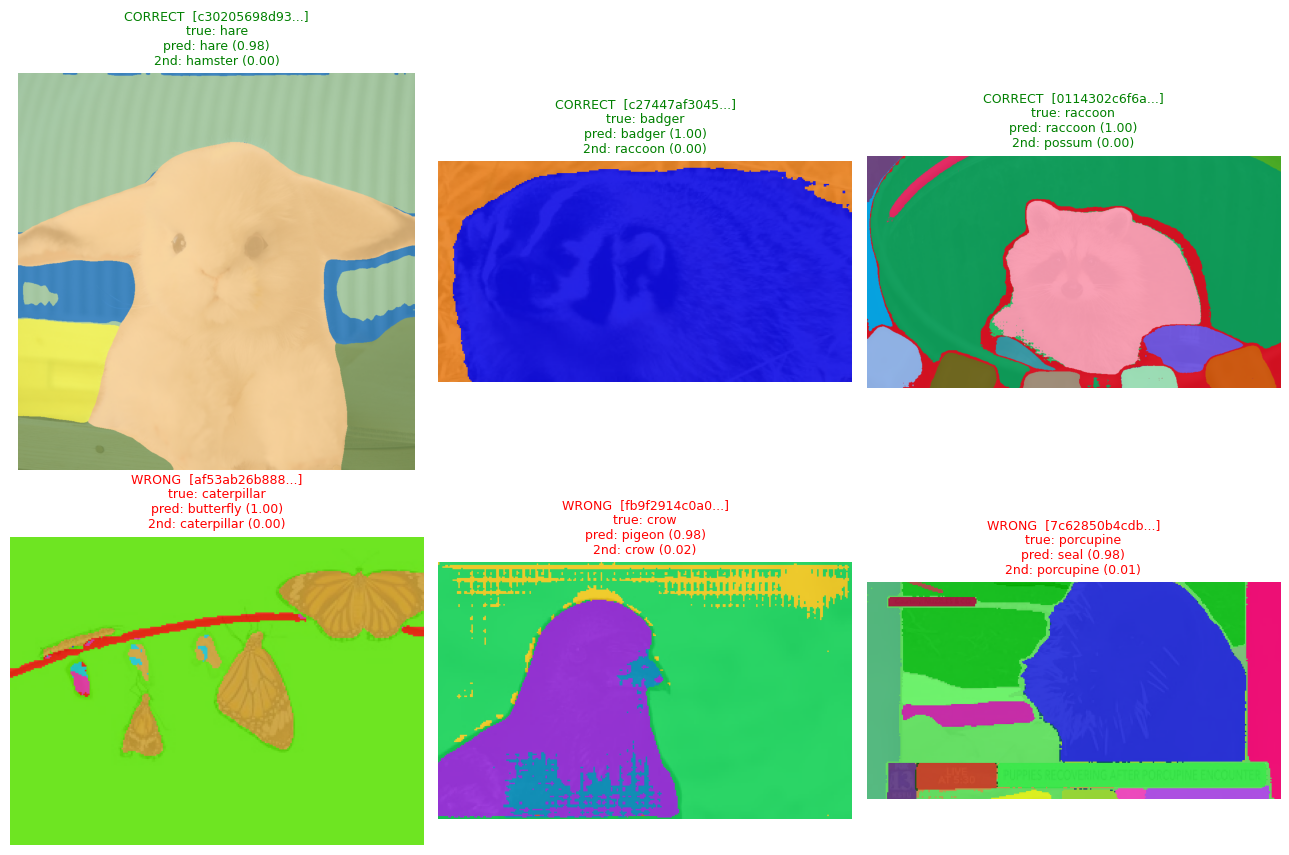

most common mistakes (true -> pred):
  coyote -> fox: 1
  wolf -> coyote: 1
  squid -> bat: 1
  woodpecker -> sparrow: 1
  swan -> goose: 1
  crow -> pigeon: 1
  turtle -> pelecaniformes: 1
  deer -> reindeer: 1

plotted images:
  CORRECT c30205698d934f408ff89d6d4f2c1e52.png | true=hare pred=hare conf=0.98
  CORRECT c27447af304540568c9b34cf98c85b52.png | true=badger pred=badger conf=1.00
  CORRECT 0114302c6f6af81c3c40bab5.png | true=raccoon pred=raccoon conf=1.00
  WRONG   af53ab26b8884126bbed01e4ad937927.png | true=caterpillar pred=butterfly conf=1.00
  WRONG   fb9f2914c0a04f62ad403362221100e2.png | true=crow pred=pigeon conf=0.98
  WRONG   7c62850b4cdbc1d6b7752612.png | true=porcupine pred=seal conf=0.98

all 19 wrong dev images (also saved to dev_mistakes.csv):
                                image_id         true            pred   conf
0   af53ab26b8884126bbed01e4ad937927.png  caterpillar       butterfly  0.999
1   fb9f2914c0a04f62ad403362221100e2.png         crow          pigeon  

In [4]:
import matplotlib.pyplot as plt
from collections import Counter

assert B_dev is not None, "no OOF models loaded"
ens_dev = B_dev
pred_dev = ens_dev.argmax(1)
conf_dev = ens_dev.max(1)
ok = pred_dev == y_dev
print(f"dev accuracy: {ok.mean():.4f} | wrong: {(~ok).sum()} / {len(ok)} | recipe: {recipe}")

rng = np.random.RandomState(0)
correct_pick = rng.choice(np.where(ok)[0], 3, replace=False)
wrong_all = np.where(~ok)[0]
wrong_pick = wrong_all[np.argsort(-conf_dev[wrong_all])][:3]          # most confident mistakes
# random wrong examples instead: wrong_pick = rng.choice(wrong_all, 3, replace=False)

img_id = lambda j: os.path.basename(train_paths[dev_idx[j]])

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, j, good in [(a, j, True) for a, j in zip(axes[0], correct_pick)] + \
                   [(a, j, False) for a, j in zip(axes[1], wrong_pick)]:
    ax.imshow(Image.open(train_paths[dev_idx[j]]).convert("RGB"))
    top2 = np.argsort(-ens_dev[j])[:2]
    ax.set_title(f"{'CORRECT' if good else 'WRONG'}  [{img_id(j)[:12]}...]\ntrue: {CLASSES[y_dev[j]]}\n"
                 f"pred: {CLASSES[pred_dev[j]]} ({conf_dev[j]:.2f})\n"
                 f"2nd: {CLASSES[top2[1]]} ({ens_dev[j][top2[1]]:.2f})",
                 color="green" if good else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

print("most common mistakes (true -> pred):")
for (t, p), n in Counter((CLASSES[y_dev[j]], CLASSES[pred_dev[j]]) for j in wrong_all).most_common(8):
    print(f"  {t} -> {p}: {n}")

rows = [("CORRECT", j) for j in correct_pick] + [("WRONG", j) for j in wrong_pick]
print("\nplotted images:")
for tag, j in rows:
    print(f"  {tag:7s} {img_id(j)} | true={CLASSES[y_dev[j]]} pred={CLASSES[pred_dev[j]]} conf={conf_dev[j]:.2f}")

wrong_df = pd.DataFrame({
    "image_id": [img_id(j) for j in wrong_all],
    "true":     [CLASSES[y_dev[j]] for j in wrong_all],
    "pred":     [CLASSES[pred_dev[j]] for j in wrong_all],
    "conf":     np.round(conf_dev[wrong_all], 3),
    "path":     [train_paths[dev_idx[j]] for j in wrong_all],
}).sort_values("conf", ascending=False).reset_index(drop=True)
wrong_df.to_csv("/kaggle/working/dev_mistakes.csv", index=False)
print(f"\nall {len(wrong_df)} wrong dev images (also saved to dev_mistakes.csv):")
print(wrong_df[["image_id", "true", "pred", "conf"]].to_string())

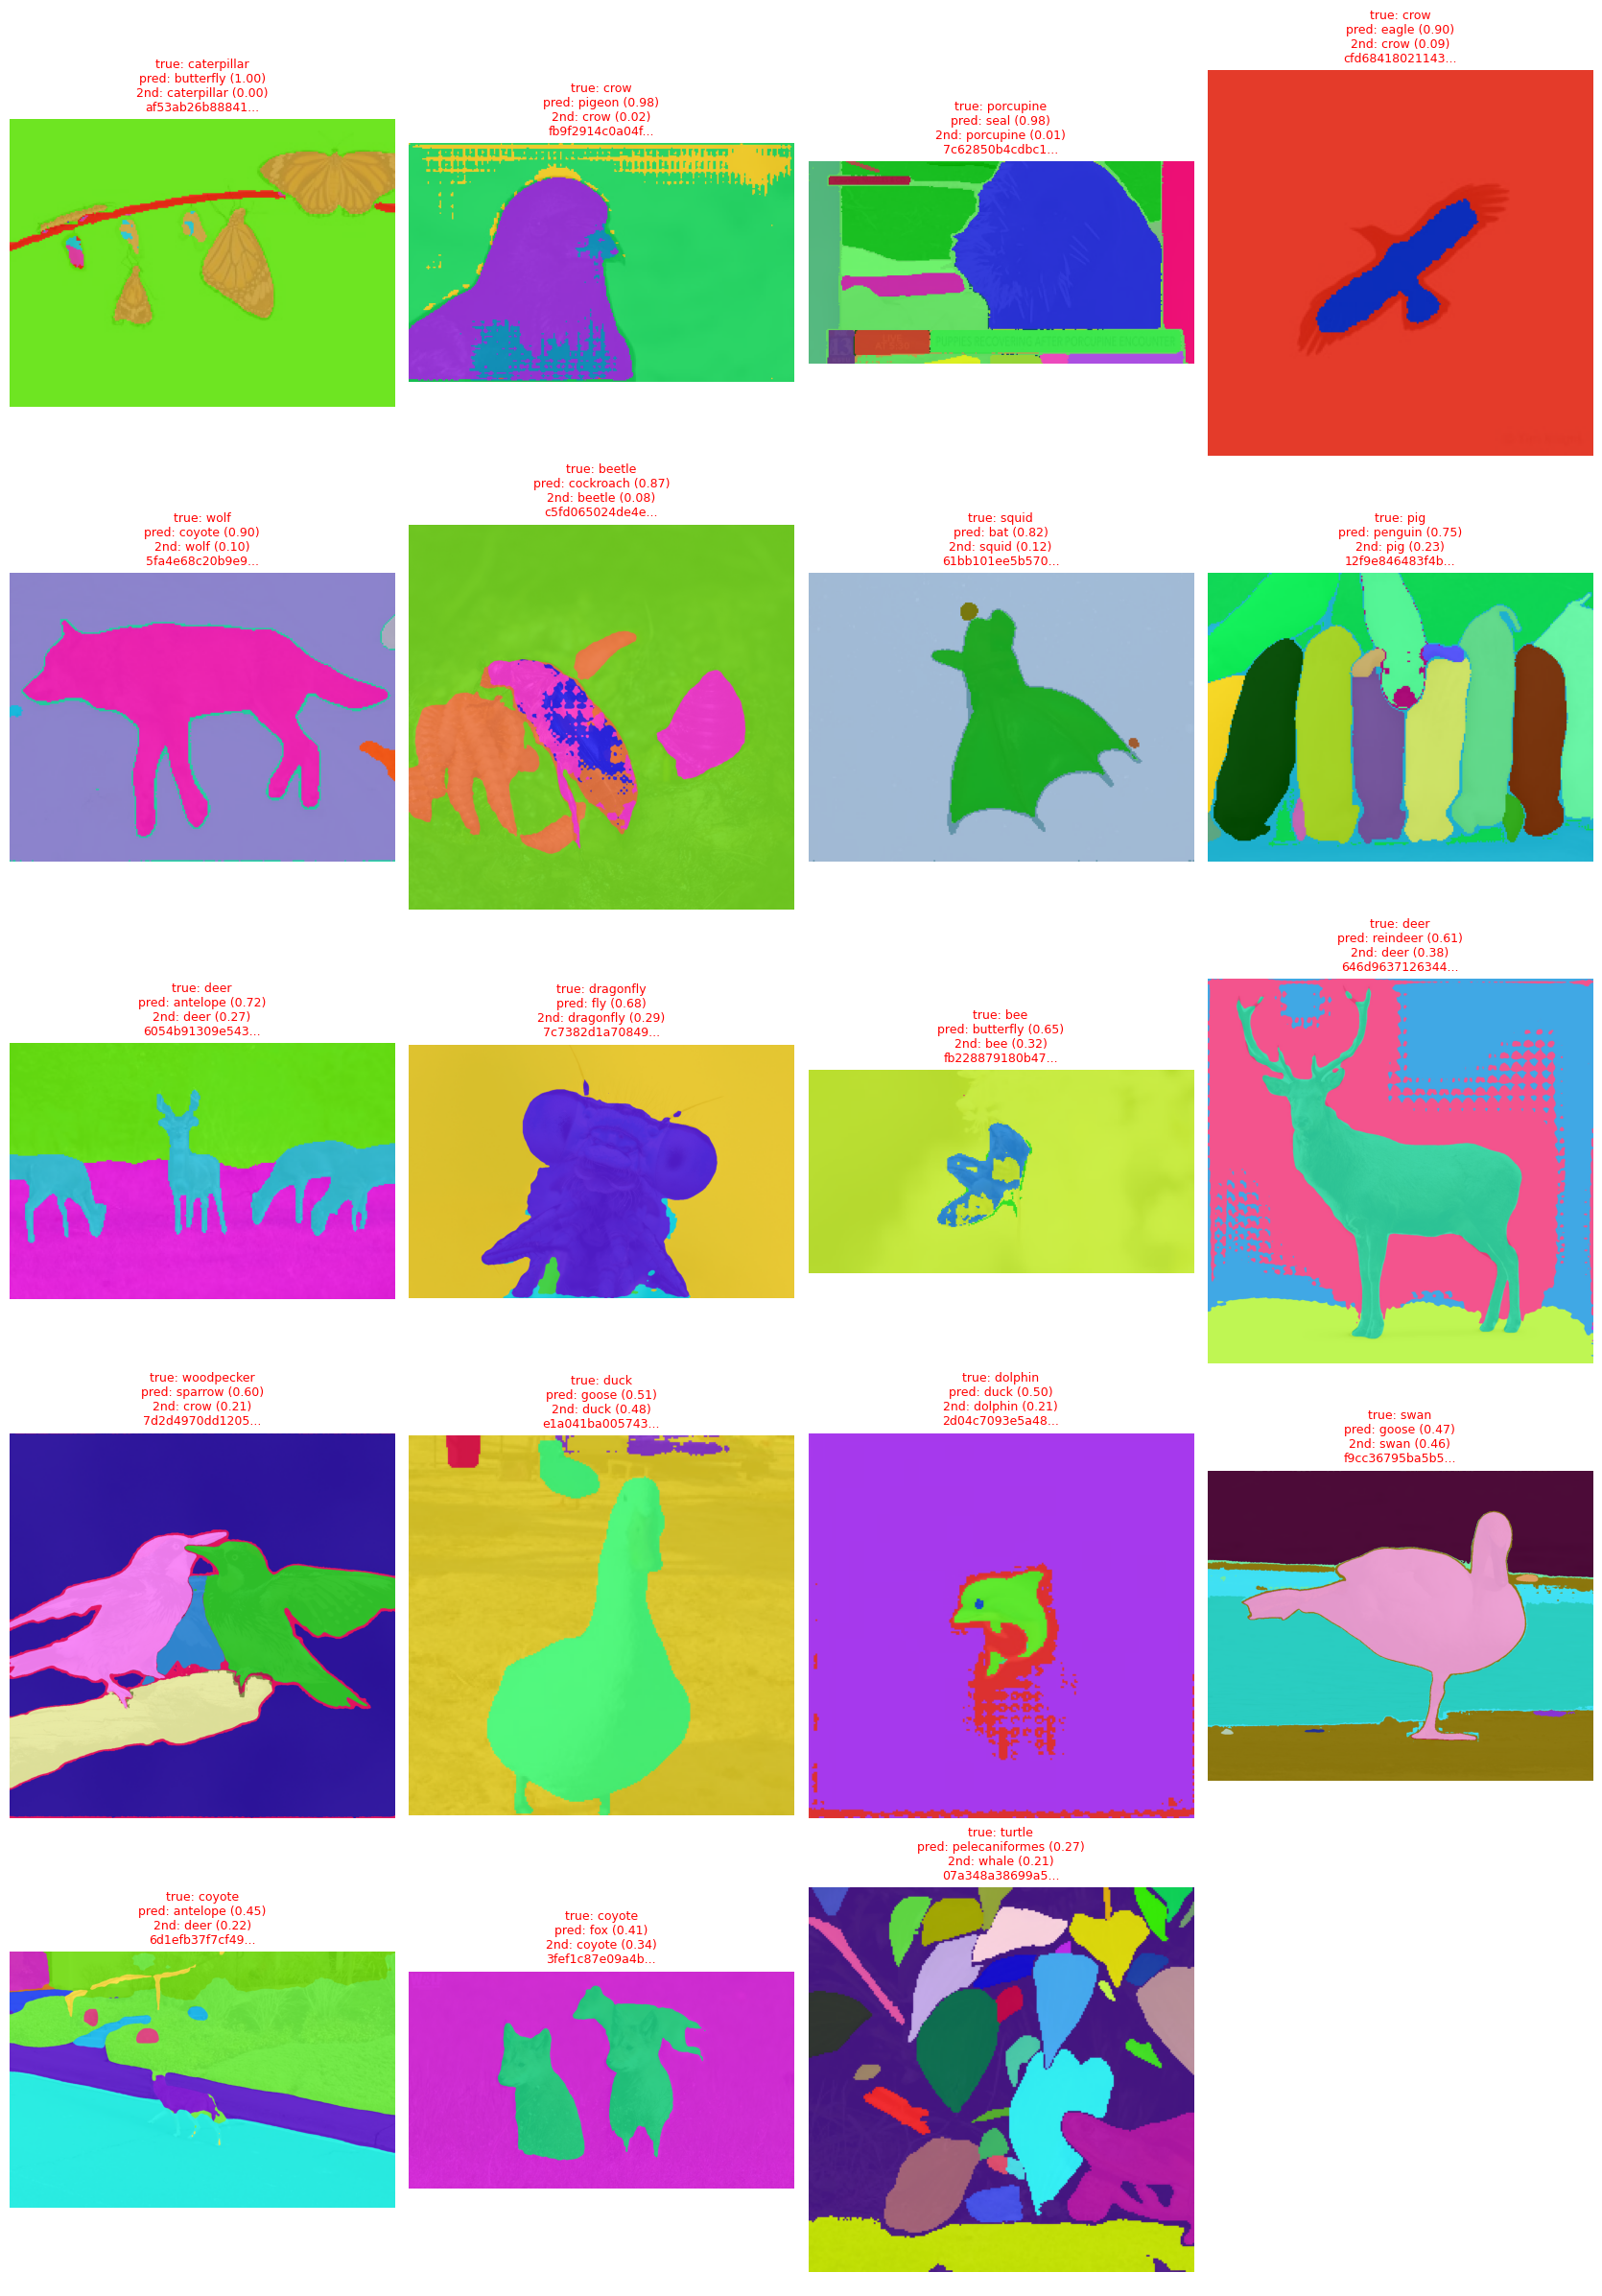

plotted 19 of 19 wrong dev images (most confident first)
saved grid to /kaggle/working/dev_mistakes_grid.png (download it from the Output tab); all mistakes are in dev_mistakes.csv


In [5]:
import matplotlib.pyplot as plt
import math

MAX_SHOW = None          # plot at most this many mistakes (set to None to plot all)
COLS = 4
OUT_PNG = "/kaggle/working/dev_mistakes_grid.png"

img_id = lambda j: os.path.basename(train_paths[dev_idx[j]])
order = wrong_all[np.argsort(-conf_dev[wrong_all])]        # most confident mistakes first
total_wrong = len(order)
if MAX_SHOW is not None: order = order[:MAX_SHOW]
rows = max(1, math.ceil(len(order) / COLS))

fig, axes = plt.subplots(rows, COLS, figsize=(4.2 * COLS, 4.8 * rows))
axes = np.array(axes).reshape(-1)
for ax, j in zip(axes, order):
    top2 = np.argsort(-ens_dev[j])[:2]
    ax.imshow(Image.open(train_paths[dev_idx[j]]).convert("RGB"))
    ax.set_title(f"true: {CLASSES[y_dev[j]]}\n"
                 f"pred: {CLASSES[pred_dev[j]]} ({conf_dev[j]:.2f})\n"
                 f"2nd: {CLASSES[top2[1]]} ({ens_dev[j][top2[1]]:.2f})\n"
                 f"{img_id(j)[:14]}...",
                 color="red", fontsize=9)
    ax.axis("off")
for ax in axes[len(order):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=110, bbox_inches="tight")
plt.show()
print(f"plotted {len(order)} of {total_wrong} wrong dev images (most confident first)")
print(f"saved grid to {OUT_PNG} (download it from the Output tab); all mistakes are in dev_mistakes.csv")